# 📊 Notebook 03: Comprehensive Exploratory Data Analysis (EDA)

**Project:** Customer Churn & Lifetime Value (LTV) Engine  
**Author:** Adarsh Kumar Pandey (*Data Analyst*)  
**Dataset:** `data/telco_customer_churn_clean.csv`  
**Objective:** Uncover key drivers of churn across contract types, tenure horizons, monthly charges, internet service tiers, and payment friction points using statistical aggregations and publication-grade visualizations.

## 1. Setup & Data Ingestion

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Plot aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
%matplotlib inline

# Load sanitized dataset
df = pd.read_csv('../data/telco_customer_churn_clean.csv')
print(f'Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns')
df.head()

Dataset Shape: 7043 rows, 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Baseline Churn Distribution

       Subscribers  Percentage (%)
Churn                             
No            5174           73.46
Yes           1869           26.54


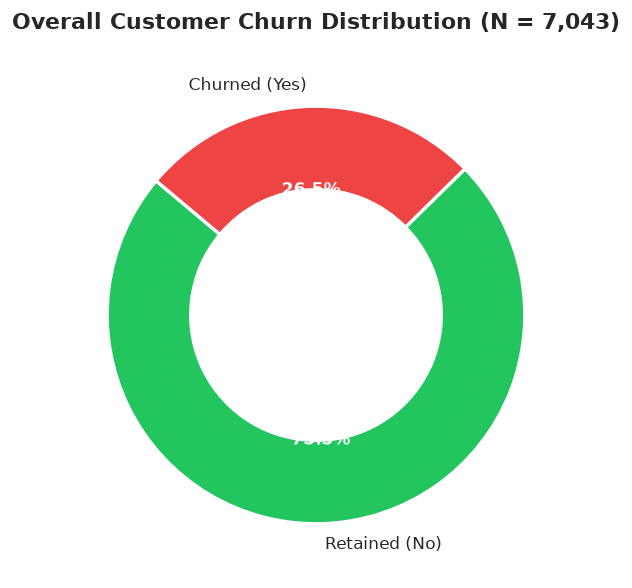

In [2]:
churn_counts = df['Churn'].value_counts()
churn_pct = df['Churn'].value_counts(normalize=True) * 100

churn_summary = pd.DataFrame({'Subscribers': churn_counts, 'Percentage (%)': churn_pct.round(2)})
print(churn_summary)

# Donut Chart for Baseline Churn
fig, ax = plt.subplots(figsize=(6, 5))
wedges, texts, autotexts = ax.pie(
    churn_counts, labels=['Retained (No)', 'Churned (Yes)'],
    autopct='%1.1f%%', colors=['#22c55e', '#ef4444'],
    startangle=140, wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2)
)
for at in autotexts:
    at.set_weight('bold')
    at.set_color('white')
ax.set_title('Overall Customer Churn Distribution (N = 7,043)', fontsize=13, weight='bold', pad=15)
plt.tight_layout()
plt.show()

## 3. Contract Type vs Churn Risk
Contract commitment is the single strongest structural predictor of subscriber stability.

         Contract  Total  Churned  Churn_Rate_Pct
0  Month-to-month   3875     1655           42.71
1        One year   1473      166           11.27
2        Two year   1695       48            2.83

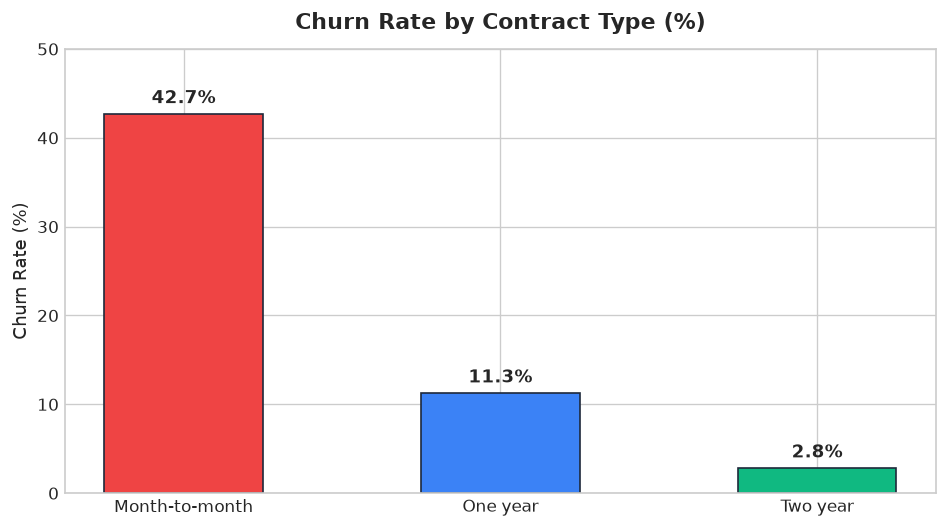

In [3]:
contract_analysis = df.groupby('Contract')['Churn'].agg(
    Total='count',
    Churned=lambda x: (x == 'Yes').sum(),
    Churn_Rate_Pct=lambda x: round((x == 'Yes').mean() * 100, 2)
).reset_index().sort_values('Churn_Rate_Pct', ascending=False)

print(contract_analysis)

# Bar Chart
plt.figure(figsize=(8, 4.5))
bars = plt.bar(contract_analysis['Contract'], contract_analysis['Churn_Rate_Pct'],
               color=['#ef4444', '#3b82f6', '#10b981'], width=0.5, edgecolor='#1e293b')
plt.title('Churn Rate by Contract Type (%)', fontsize=13, weight='bold', pad=12)
plt.ylabel('Churn Rate (%)', fontsize=11)
plt.ylim(0, 50)
for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.2,
             f"{bar.get_height():.1f}%", ha='center', fontsize=11, weight='bold')
plt.tight_layout()
plt.show()

**Insight:** Month-to-month subscribers experience a staggering **42.71% churn rate**, whereas Two-year contract holders drop to just **2.83%** (a 15x churn reduction).

## 4. Customer Tenure & The Early Lifecycle Drop-off Horizon
Examining when subscribers churn across their lifecycle.

  tenure_cohort  Total  Churned  Churn_Rate_Pct
0         0-12m   2186     1037           47.44
1        13-24m   1024      294           28.71
2        25-36m    832      180           21.63
3        37-48m    762      145           19.03
4        49-60m    832      120           14.42
5        61-72m   1407       93            6.61


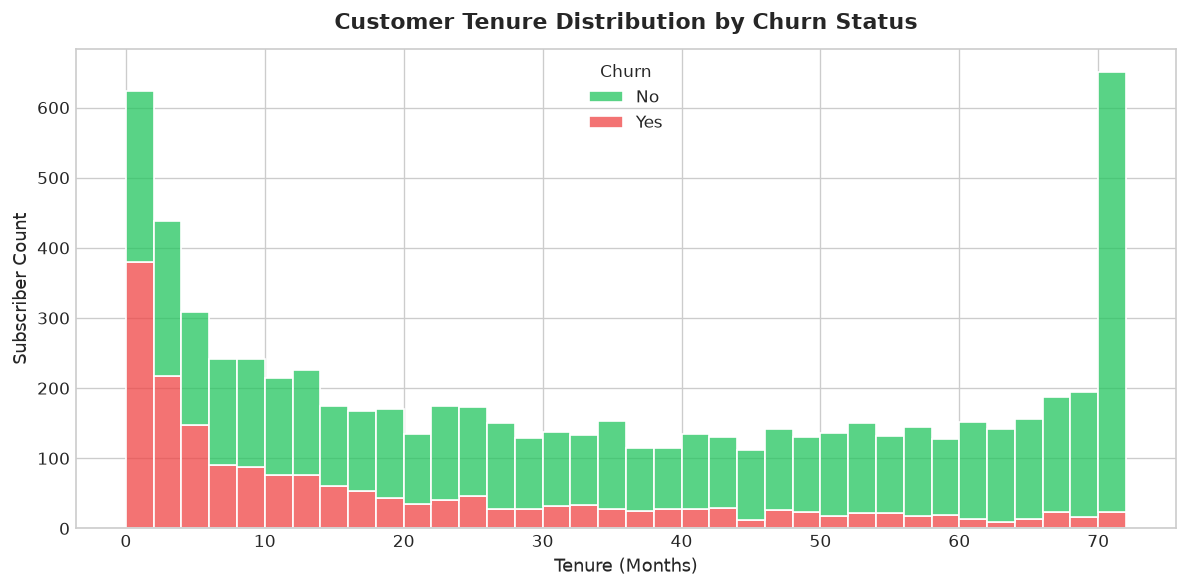

In [4]:
# Create tenure cohorts
bins = [-1, 12, 24, 36, 48, 60, 72]
labels = ['0-12m', '13-24m', '25-36m', '37-48m', '49-60m', '61-72m']
df['tenure_cohort'] = pd.cut(df['tenure'], bins=bins, labels=labels)

tenure_summary = df.groupby('tenure_cohort', observed=False)['Churn'].agg(
    Total='count',
    Churned=lambda x: (x == 'Yes').sum(),
    Churn_Rate_Pct=lambda x: round((x == 'Yes').mean() * 100, 2)
).reset_index()

print(tenure_summary)

# Distribution Histogram
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='tenure', hue='Churn', multiple='stack', bins=36,
             palette={'No': '#22c55e', 'Yes': '#ef4444'}, edgecolor='white')
plt.title('Customer Tenure Distribution by Churn Status', fontsize=13, weight='bold', pad=12)
plt.xlabel('Tenure (Months)', fontsize=11)
plt.ylabel('Subscriber Count', fontsize=11)
plt.tight_layout()
plt.show()

**Insight:** 55.48% of all churn happens within the **first 12 months (0-12m cohort)**. Subscribers who survive beyond 24 months show high brand loyalty and lifetime value.

## 5. Monthly Charges & Price Sensitivity
Investigating the pricing threshold where churn accelerates.

--- Monthly Charges Statistical Summary by Churn ---
        count   mean    std    min    25%    50%   75%     max
Churn                                                         
No     5174.0  61.27  31.09  18.25  25.10  64.43  88.4  118.75
Yes    1869.0  74.44  24.67  18.85  56.15  79.65  94.2  118.35


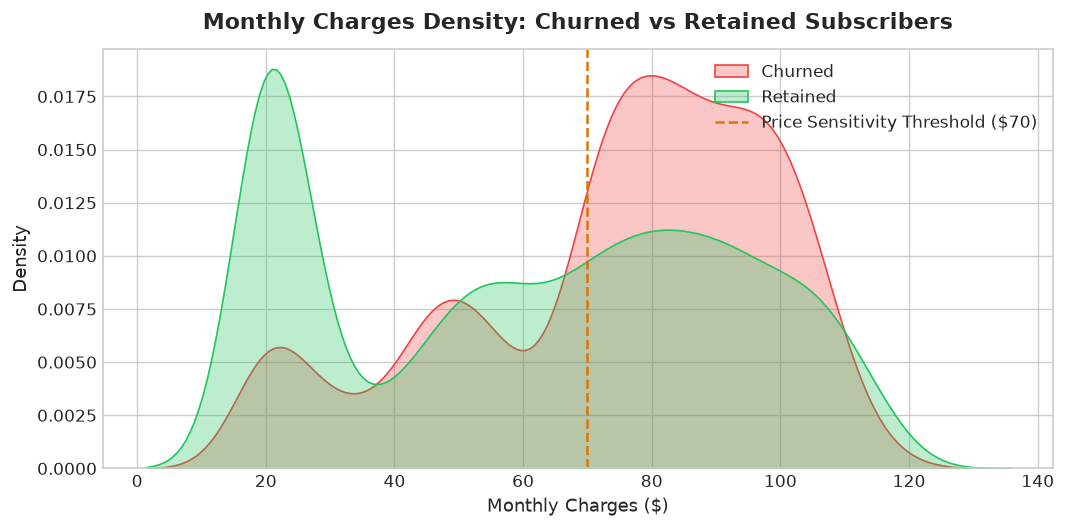

In [5]:
print('--- Monthly Charges Statistical Summary by Churn ---')
print(df.groupby('Churn')['MonthlyCharges'].describe().round(2))

# KDE / Density Plot
plt.figure(figsize=(9, 4.5))
sns.kdeplot(data=df[df['Churn'] == 'Yes']['MonthlyCharges'], label='Churned', color='#ef4444', fill=True, alpha=0.3)
sns.kdeplot(data=df[df['Churn'] == 'No']['MonthlyCharges'], label='Retained', color='#22c55e', fill=True, alpha=0.3)
plt.axvline(70, color='#d97706', linestyle='--', linewidth=1.5, label='Price Sensitivity Threshold ($70)')
plt.title('Monthly Charges Density: Churned vs Retained Subscribers', fontsize=13, weight='bold', pad=12)
plt.xlabel('Monthly Charges ($)', fontsize=11)
plt.ylabel('Density', fontsize=11)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

**Insight:** Churned customers have a median monthly charge of **$79.65** compared to **$64.45** for retained customers. Subscribers paying $\ge \$70/\text{month}$ without technical support exhibit peak attrition.

## 6. Internet Service & Payment Method Friction Analysis

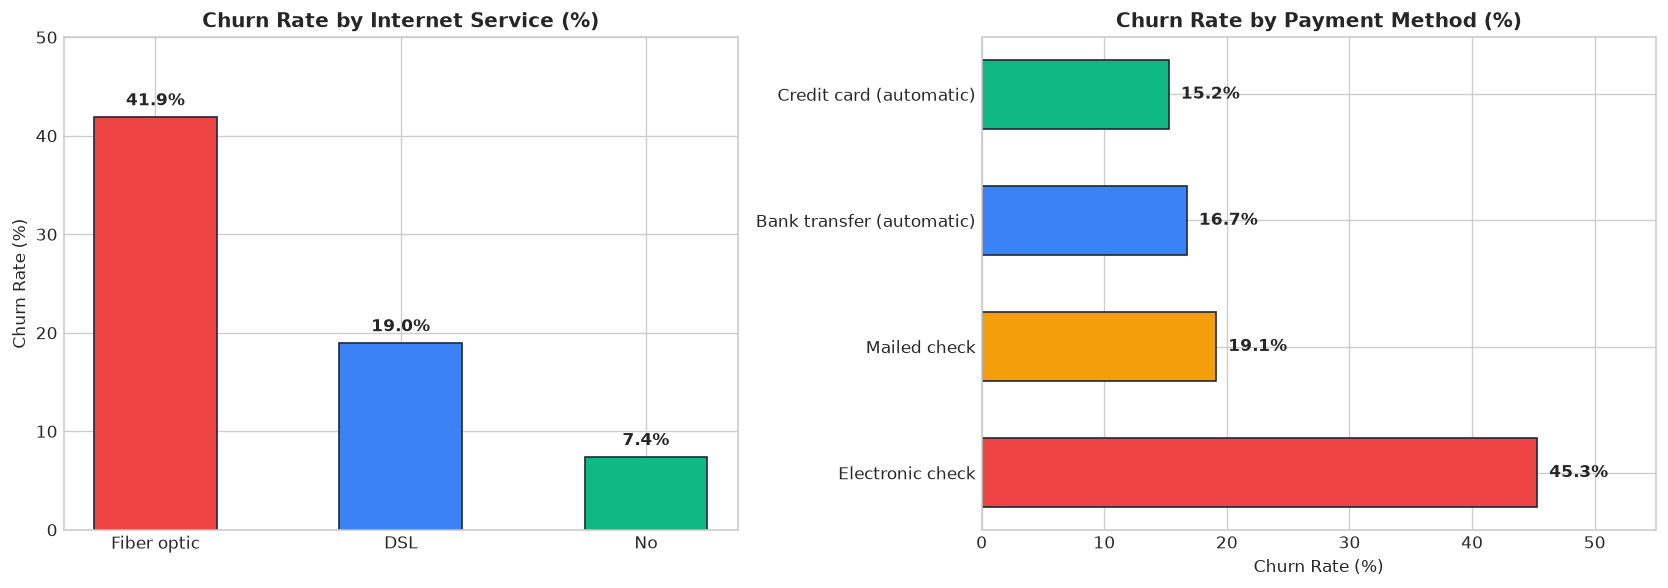

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Internet Service
net_churn = df.groupby('InternetService')['Churn'].apply(lambda x: (x == 'Yes').mean() * 100).sort_values(ascending=False)
axes[0].bar(net_churn.index, net_churn.values, color=['#ef4444', '#3b82f6', '#10b981'], width=0.5, edgecolor='#1e293b')
axes[0].set_title('Churn Rate by Internet Service (%)', fontsize=12, weight='bold')
axes[0].set_ylabel('Churn Rate (%)', fontsize=10)
axes[0].set_ylim(0, 50)
for i, v in enumerate(net_churn.values):
    axes[0].text(i, v + 1.2, f'{v:.1f}%', ha='center', weight='bold')

# Payment Method
pay_churn = df.groupby('PaymentMethod')['Churn'].apply(lambda x: (x == 'Yes').mean() * 100).sort_values(ascending=False)
axes[1].barh(pay_churn.index, pay_churn.values, color=['#ef4444', '#f59e0b', '#3b82f6', '#10b981'], height=0.55, edgecolor='#1e293b')
axes[1].set_title('Churn Rate by Payment Method (%)', fontsize=12, weight='bold')
axes[1].set_xlabel('Churn Rate (%)', fontsize=10)
axes[1].set_xlim(0, 55)
for i, v in enumerate(pay_churn.values):
    axes[1].text(v + 1, i, f'{v:.1f}%', va='center', weight='bold')

plt.tight_layout()
plt.show()

## 7. Strategic Conclusions & Playbook

1. **Contract Lock-in:** Month-to-month contracts account for 88.5% of churn volume. Migrating subscribers to 1- or 2-year plans is priority #1.
2. **The 12-Month Onboarding Window:** 55.5% of churn occurs in year 1. Proactive customer success check-ins must be front-loaded in days 30, 60, and 90.
3. **Payment Friction:** Electronic Check users churn at 45.3% vs <18% for automated credit cards or bank transfers. An auto-pay incentive bonus will yield immediate ROI.